#### Joint marker controller -> real `FFW SG2`

Real-robot version of `sim_marker_joint_controller_sg2_teleop.ipynb`. Every commandable joint
carries its own gizmo at the joint itself -- a ring around each hinge axis, an arrow along the
`lift_joint` slide -- and dragging one writes that single joint's qpos. No IK: unlike
`real_interactive_marker_sg2_teleop.ipynb`, nothing is solved, so what you turn is exactly what the
robot is told to turn.

Run order:
1. On the robot: `worker_bringup`, then `worker_outbound`, then `worker_inbound`.
2. `real_render_MetaQuest3_sg2.ipynb` in another kernel/window (optional, shows real vs command).
3. This notebook. Cell 5 seeds the sim from the robot's own joint state, so the markers start on the
   real pose and nothing jumps. Re-run cell 5 to re-seed from the robot later.
4. `Robot` starts at `OFF`. Switch it `ON` only after the markers sit where you expect.

Two things differ from the sim notebook, both for safety:

- **Joint speed limit.** Every published command is ramped, at 60 deg/s per hinge and 0.05 m/s on
  the lift. A drag never comes close; a `Preset` or a `File` load would otherwise be an instant
  whole-arm swing. MuJoCo is driven by the ramped pose, so the viewer shows the robot's command,
  not the marker's wish. `RATE LIMITED` appears in the overlay while a ramp is running.
- **`Preset` has no `zero`.** Straightening a folded arm to all-zero is exactly the motion
  `ffw_sg2_follower_initial_positions.yaml` splits into two steps to avoid. `init` is that yaml's
  end state; `sync` just re-anchors the markers to the current pose.

🚨 Keep someone on the E-stop from the moment `Robot` goes `ON`.

공통 JSON worker를 사용합니다(0/1 모드 변경 불필요). Robot ON은 현재 실측 자세로 마커·슬라이더를 동기화하고 ACK를 기다립니다. ARMING 후 조작하세요. OFF는 명령 세션과 5561 포트를 해제합니다. 오류 뒤에는 OFF→ON으로 재시작합니다.

주 제어창의 로봇 모델은 입력 목표 미리보기입니다. 별도 renderer의 목표 자세에는 공통 클라이언트가 실제 송신한 관절값을 전달합니다.


**셀 1. 프로젝트 초기화 및 모듈 임포트**

프로젝트 초기화 스크립트(`init_project.py`)를 실행하고 시뮬레이션/키네마틱스/유틸리티/Qt 패키지를 임포트한다. 조인트 마커 컨트롤러(`joint_marker_control`)와 실기용 추가 모듈(`joint_marker_real`)도 함께 가져온다. 마지막으로 Qt 애플리케이션 인스턴스(`app`)를 생성한다.

In [13]:
# Locate the shared workspace from a notebook, project or repository directory.
from pathlib import Path
import runpy

_notebook_dir = (Path(__vsc_ipynb_file__).resolve().parent
                 if "__vsc_ipynb_file__" in globals() else Path.cwd())
_search_bases = [_notebook_dir, *_notebook_dir.parents, Path.cwd(), *Path.cwd().parents]
_candidates = [candidate for base in _search_bases
               for candidate in (base, base / "VR_teleoperation")]
_root = next((candidate for candidate in _candidates
              if (candidate / ".project_v2").is_file()), None)
if _root is None:
    raise RuntimeError("Open this notebook from the VR_teleoperation workspace.")
_bootstrap = runpy.run_path(str(_root / "package" / "init_project.py"))
for _name in _bootstrap["__all__"]:
    globals()[_name] = _bootstrap[_name]

import numpy as np

from ri_motion_v5_package.init_scripts.init_ipython_setup import *
from ri_motion_v5_package.init_scripts.init_qt import *
from ri_motion_v5_package.mujoco_sim import *
from ri_motion_v5_package.kinematics import *
from ri_motion_v5_package.utility import *
from ri_motion_v5_package.qt import *
from utils import *
from package.joint_control import *        # not `from joint_control import *`: IPython's %run puts
from package.joint_marker_control import * # PACKAGE_DIR on sys.path only during the run
from package.joint_marker_real import *

app = get_qt_app()
from package.robot_client import SG2JointCommandClient, get_latest_strict_robot_qpos
from package.worker.fixed_quest_protocol import JOINT_NAMES as ROBOT_JOINT_NAMES



[VR_teleoperation / ffw_sg2_vr_teleoperation] initialized.
 - PROJECT_DIR: /home/vai/Desktop/yujin/VAI_AIWORKER/VR_teleoperation


**셀 2. 자기충돌 감시용 네이티브 백엔드 빌드**

signed distance 계산에 쓰는 네이티브 백엔드를 빌드(또는 로드)한다. 이 노트북은 IK를 풀지 않으므로 백엔드는 **자기충돌 경고 표시에만** 쓰인다. 실기 노트북이므로 `required=True`로 두어 빌드 실패를 조용히 넘기지 않는다.

In [14]:
native_backend = build_sg2_collision_aware_ik_backend(
    clean   = False,
    verbose = True,
    required = True,)
print("bind info:",native_backend.native_info())

[build_native]
  module      : _mujoco_collision_aware_ik_bind
  output      : mujoco_sim/so/_mujoco_collision_aware_ik_bind.cpython-312-x86_64-linux-gnu.so
  compiler    : g++ -pthread -B /home/vai/anaconda3/envs/ri_motion_v5_py312/compiler_compat
  project cpp:
    [01] mujoco_sim/cpp/bindings.cpp
    [02] mujoco_sim/cpp/signed_distance_bindings.cpp
    [03] mujoco_sim/cpp/signed_distance.cpp
    [04] mujoco_sim/cpp/ik_bindings.cpp
    [05] mujoco_sim/cpp/ik.cpp
  project hpp:
    [01] mujoco_sim/cpp/signed_distance_bindings.hpp
    [02] mujoco_sim/cpp/signed_distance.hpp
    [03] mujoco_sim/cpp/ik_bindings.hpp
    [04] mujoco_sim/cpp/ik.hpp
    [05] mujoco_sim/cpp/mujoco_handles.hpp
  defines:
    [01] RI_NATIVE_ENABLE_SIGNED_DISTANCE
    [02] RI_NATIVE_ENABLE_IK
    [03] RI_NATIVE_MODULE_NAME=_mujoco_collision_aware_ik_bind
  nanobind cpp:
    [01] nanobind/src/nb_combined.cpp
  commands    : hidden; pass show_commands=True to print full commands
[build_native] compile
  [01/06] mu

**셀 3. 통신(ZMQ) 포트 및 IP 설정**

렌더러로 상태를 퍼블리시할 포트(`RENDER_PORT`), 실제 SG2로 명령을 퍼블리시할 포트/IP(`PUB_TO_SG2_PORT`, `PUB_TO_SG2_IP`), SG2의 현재 상태를 구독할 포트/IP(`SUB_FROM_SG2_PORT`, `SUB_FROM_SG2_IP`)를 정의한다. `PUB_TO_SG2_IP`로 출력되는 값이 로봇 쪽 `inbound.py`의 `ZMQ_SUB_IP`와 일치해야 한다.

In [15]:
RENDER_PORT = 5556
PUB_TO_SG2_PORT = 5561
PUB_TO_SG2_IP = get_ip_address()
SUB_FROM_SG2_PORT = 5560
SUB_FROM_SG2_IP = "192.168.6.2"

ALLOW_MISSING_ROBOT_STATE = False

print("PUB_TO_SG2_IP",PUB_TO_SG2_IP)
print("Robot state SUB: tcp://%s:%d"%(SUB_FROM_SG2_IP,SUB_FROM_SG2_PORT))

PUB_TO_SG2_IP 192.168.6.103
Robot state SUB: tcp://192.168.6.2:5560


**셀 4. MuJoCo 시뮬레이션 환경 로드**

바닥(`FLOOR_XML_PATH`)과 SG2 로봇(`SG2_XML_PATH`) MJCF를 병합해 씬 XML을 만들고 `MuJoCoParser` 환경(`env`)을 생성한다.

In [16]:
xml_path = merge_mjcfs(
    included_mjcf_files = [
        str(FLOOR_XML_PATH),
        str(SG2_XML_PATH),
    ],
    output_xml_path = str(SG2_SCENE_XML_PATH),)
env = MuJoCoParser(rel_xml_path=xml_path,verbose=False)

[merge_mjcfs] Merging [2] MJCF files:
  - [0] [/home/vai/Desktop/yujin/VAI_AIWORKER/VR_teleoperation/xml/floor_simple_white.xml]
  - [1] [/home/vai/Desktop/yujin/VAI_AIWORKER/VR_teleoperation/xml/ffw_sg2.xml]
[merge_mjcfs] Saved merged XML to:[/home/vai/Desktop/yujin/VAI_AIWORKER/VR_teleoperation/xml/scene_ffw_sg2_metaquest3.xml]
MuJoCo model loaded from [/home/vai/Desktop/yujin/VAI_AIWORKER/VR_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].


**셀 5. 관절 메시지 레이아웃 구성 및 실제 로봇 자세 동기화**

실기로 보낼 명령 관절 목록(`command_joint_names`, lift 1 + head 2 + arm 14 + gripper 2 = 19)과 이를 `inbound.py`의 6개 그룹으로 나누는 `q_msg_layout`을 만든다. 이어서 SG2로부터 현재 관절 상태를 받아(`get_latest_robot_qpos`) 시뮬 자세를 실기 자세에 맞춘다. **마커는 다음 셀에서 이 자세를 기준으로 생성되므로 이 셀이 먼저 성공해야 한다.** 실행 중 로봇과 어긋났다고 느껴지면 이 셀만 다시 실행해 재동기화하면 된다.

In [17]:
env.reset()
env.set_p("base_link","body",(0.0,0.0,0.01))

real_command_joint_names = (
    list(SG2_REAL_COMMAND_JOINT_NAMES)
    + [SG2_GRIPPER_DRIVER_JOINT_NAMES[hand_type] for hand_type in SG2_HAND_TYPES]
)
command_joint_names = filter_existing_joint_names(env,real_command_joint_names)
q_msg_format_dict = {
    "lift"      : {"prefixes":["lift_joint"]},
    "head"      : {"prefixes":["head_joint"]},
    "arm_l"     : {"prefixes":["arm_l_joint"]},
    "arm_r"     : {"prefixes":["arm_r_joint"]},
    "gripper_l" : {"prefixes":["gripper_l_joint1"]},
    "gripper_r" : {"prefixes":["gripper_r_joint1"]},
}
q_msg_layout = build_q_msg_layout(
    env               = env,
    q_msg_format_dict = q_msg_format_dict,
    use_joint_names   = command_joint_names,)
q_use_min = env.get_joint_mins(command_joint_names)
q_use_max = env.get_joint_maxs(command_joint_names)

print("Joint message layout")
print("--------------------")
for q_msg_key in q_msg_layout["q_msg_keys"]:
    joint_names = q_msg_layout["qmsgkeys_to_usejointnames_dict"][q_msg_key]
    joint_idxs = q_msg_layout["qmsgkeys_to_usejointidxs_dict"][q_msg_key]
    print("%-8s | %2d joints | idxs:%s | %s"%(q_msg_key,len(joint_names),joint_idxs,joint_names))
print("--------------------")
print("%-8s | %2d joints"%("total",len(command_joint_names)))
print("unused:",q_msg_layout["unused_joint_names"])

try:
    q_use,recv_count = get_latest_strict_robot_qpos(
        env             = env,
        q_msg_layout    = q_msg_layout,
        use_joint_names = command_joint_names,
        sub_ip          = SUB_FROM_SG2_IP,
        sub_port        = SUB_FROM_SG2_PORT,
        timeout_sec     = 1.0,
        verbose         = True,)
    print("[Robot init] OK. recv_count:[%d]"%recv_count)
except Exception:
    if not ALLOW_MISSING_ROBOT_STATE:
        raise
    q_use = env.get_qpos(joint_names=command_joint_names)
    print("[Robot init] missing robot state; using current MuJoCo q because ALLOW_MISSING_ROBOT_STATE=True.")

# Start the sim at the real robot pose so the markers seed without a jump.
q_use = np.clip(q_use,q_use_min,q_use_max)
env.forward(q=q_use,joint_names=command_joint_names)
for hand_type in SG2_HAND_TYPES:
    set_sg2_gripper_qpos(env,hand_type,float(q_use[command_joint_names.index(SG2_GRIPPER_DRIVER_JOINT_NAMES[hand_type])]))

Joint message layout
--------------------
lift     |  1 joints | idxs:[0] | ['lift_joint']
head     |  2 joints | idxs:[1, 2] | ['head_joint1', 'head_joint2']
arm_l    |  7 joints | idxs:[3, 4, 5, 6, 7, 8, 9] | ['arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7']
arm_r    |  7 joints | idxs:[10, 11, 12, 13, 14, 15, 16] | ['arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7']
gripper_l |  1 joints | idxs:[17] | ['gripper_l_joint1']
gripper_r |  1 joints | idxs:[18] | ['gripper_r_joint1']
--------------------
total    | 19 joints
unused: []
[Robot init] OK. recv_count:[1]


**셀 6. 뷰어, 조인트 마커, UI 위젯, 속도 제한, ZMQ 퍼블리셔 초기화**

루프 주기(input/robot/render Hz)를 정하고, 자기충돌 감시용 지오메트리 쌍을 만든다. 뷰어를 연 뒤 **실기 자세 위에** 관절별 마커를 생성한다(그룹별 색: arm_l 파랑, arm_r 주황, lift/head/gripper 초록). `Robot` OFF/ON 게이트를 포함한 커맨드 위젯과 관절별 속도 상한(`joint_speed_limits`)을 만들고, 마지막으로 로봇 명령 퍼블리셔(`pub_robot`)와 렌더 퍼블리셔(`pub_render`)를 생성한다. 여기서는 프리셋을 적용하지 않는다 — 실기에서 초기 자세는 로봇이 이미 잡고 있다.

In [18]:
input_hz = 30
robot_hz = 100
render_hz = 20

hand_types = list(SG2_HAND_TYPES)
hand_labels = dict(SG2_HAND_LABELS)

# Self-collision is only monitored here: signed distances are reported, never corrected.
collision_geom_pairs,collision_candidate_info = create_sg2_collision_candidate_geom_pairs(
    env               = env,
    init_exclude_dist = 0.05,)
print_sg2_collision_candidate_summary(collision_candidate_info)

env.init_viewer(title="SG2 Joint Marker -> Real FFW SG2",x_offset=0.25,y_offset=0.00,width=0.75,height=1.0,fontscale=180)
env.viewer.set_cam_info(180.0,2.6,-18.0,[0.0,0.0,0.95])
env.viewer.set_transparency(transparent=True)

# One axis marker per joint, seeded on the real robot's current pose.
controller = SG2JointMarkerController(env=env,ring_r=0.05,axis_len=0.12)
ctrl_radio = create_sg2_joint_marker_real_command_widget()
joint_speed_limits = get_sg2_joint_speed_limits(env=env,joint_names=command_joint_names)

pub_robot = SG2JointCommandClient(
    robot_ip=SUB_FROM_SG2_IP, state_port=SUB_FROM_SG2_PORT,
    command_port=PUB_TO_SG2_PORT, controlled_joint_names=command_joint_names,
)
pub_render = ZMQPubSub(role="pub",port=RENDER_PORT,verbose=True)

print("ZMQ publishers")
print("--------------")
print("Robot        : tcp://*:%d"%PUB_TO_SG2_PORT)
print("Renderer pub : tcp://*:%d"%RENDER_PORT)
print("Render view  : run real_render_MetaQuest3_sg2.ipynb in another kernel/window")
print("marker joints (%d):"%len(controller.joint_names),controller.joint_names)
print("speed limit  : %.1f deg/s per hinge, %.3f m/s on the lift"%(
    np.rad2deg(SG2_MAX_REV_JOINT_SPEED),SG2_MAX_PRI_JOINT_SPEED))
print("qpos file    :",SG2_JOINT_QPOS_PATH)
print("Input: drag a ring to turn that one joint. No IK is solved.")
print("Robot starts OFF. ON synchronizes to the measured pose; move markers after ARMING completes.")
print("Shared bridge limits apply: lift ≤0.01 m/s; rotary commands are paced and acknowledged.")
print("Main viewer: target preview. Separate renderer: transmitted command and measured robot.")


Collision candidates
--------------------
robot collision geom:[34]
collision geom:[35]
candidate geom pairs:[477]
excluded initial geom pairs:[53]
[ZMQ Publisher] pid:[2544480] endpoint:[tcp://0.0.0.0:5556]
[ZMQ] role:[pub] ip:[192.168.6.103] port:[5556] hwm:[1] conflate:[True]
ZMQ publishers
--------------
Robot        : tcp://*:5561
Renderer pub : tcp://*:5556
Render view  : run real_render_MetaQuest3_sg2.ipynb in another kernel/window
marker joints (19): ['arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7', 'arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7', 'lift_joint', 'head_joint1', 'head_joint2', 'gripper_l_joint1', 'gripper_r_joint1']
speed limit  : 60.0 deg/s per hinge, 0.050 m/s on the lift
qpos file    : /home/vai/Desktop/yujin/VAI_AIWORKER/VR_teleoperation/qpos/sg2_joint_qpos.json
Input: drag a ring to turn that one joint. No IK is solved.
Robot starts OF

**셀 7. 메인 루프 — 마커 입력 → 속도 제한 → 로봇 명령 퍼블리시 → 렌더링**

뷰어가 살아있고 커맨드 위젯이 열려 있는 동안 도는 메인 루프다.

- 매 패스: 커맨드 위젯을 한 번 읽는다. `Robot` ON/OFF 전환과 `Preset`/`File` 동작 로그를 출력한다.
- `input_hz`(`tmr_input`): 마커를 폴링해 드래그 중인 관절 하나의 qpos를 쓰고, `apply_sg2_joint_rate_limit`으로 이번 틱에 허용된 만큼만 반영한 뒤(제한이 걸리면 `RATE LIMITED` 표시), 마커를 제한된 자세에 다시 앵커링한다. `Collision`이 on이면 signed distance를 계산한다.
- `robot_hz`(`tmr_robot`): `Robot`이 ON일 때만 현재 관절값을 6개 그룹 메시지로 만들어 실기로 퍼블리시한다.
- `render_hz`(`tmr_render`): 좌표축·링크·마커·충돌선을 그리고 오버레이를 얹어 렌더링한 뒤, 같은 정보를 렌더 노트북으로 보낸다.
- 종료 시 퍼블리셔와 위젯을 정리하고 뷰어를 닫는다.

[Joint Marker] Initialized with [30.0]HZ. MAX_SEC:[inf]sec.
[Robot Pub] Initialized with [100.0]HZ. MAX_SEC:[inf]sec.
[Render Pub] Initialized with [20.0]HZ. MAX_SEC:[inf]sec.
[Joint Marker] Start ([30.0]HZ. MAX_SEC:[inf]sec).
[Robot Pub] Start ([100.0]HZ. MAX_SEC:[inf]sec).
[Render Pub] Start ([20.0]HZ. MAX_SEC:[inf]sec).
[Joint Marker][1] run delayed! T:[33.3]ms run:[63.5]ms]
[Robot] OFF control disabled; command port released
[Render Pub][1] run delayed! T:[50.0]ms run:[67.8]ms]
[Joint Marker][2][0.1s] delayed! T:[33.3]ms interval:[134.9]ms prev_run:[63.5]ms.
[Robot Pub][2][0.2s] delayed! T:[10.0]ms interval:[98.6]ms prev_run:[1.3]ms.
[Render Pub][2][0.2s] delayed! T:[50.0]ms interval:[98.5]ms prev_run:[67.8]ms.
[Joint Marker][3][0.2s] delayed! T:[33.3]ms interval:[51.4]ms prev_run:[27.3]ms.
[Robot Pub][3][0.2s] delayed! T:[10.0]ms interval:[35.2]ms prev_run:[1.2]ms.
[Robot Pub][4][0.2s] delayed! T:[10.0]ms interval:[34.6]ms prev_run:[0.6]ms.
[Robot Pub][5][0.3s] delayed! T:[10.0]ms

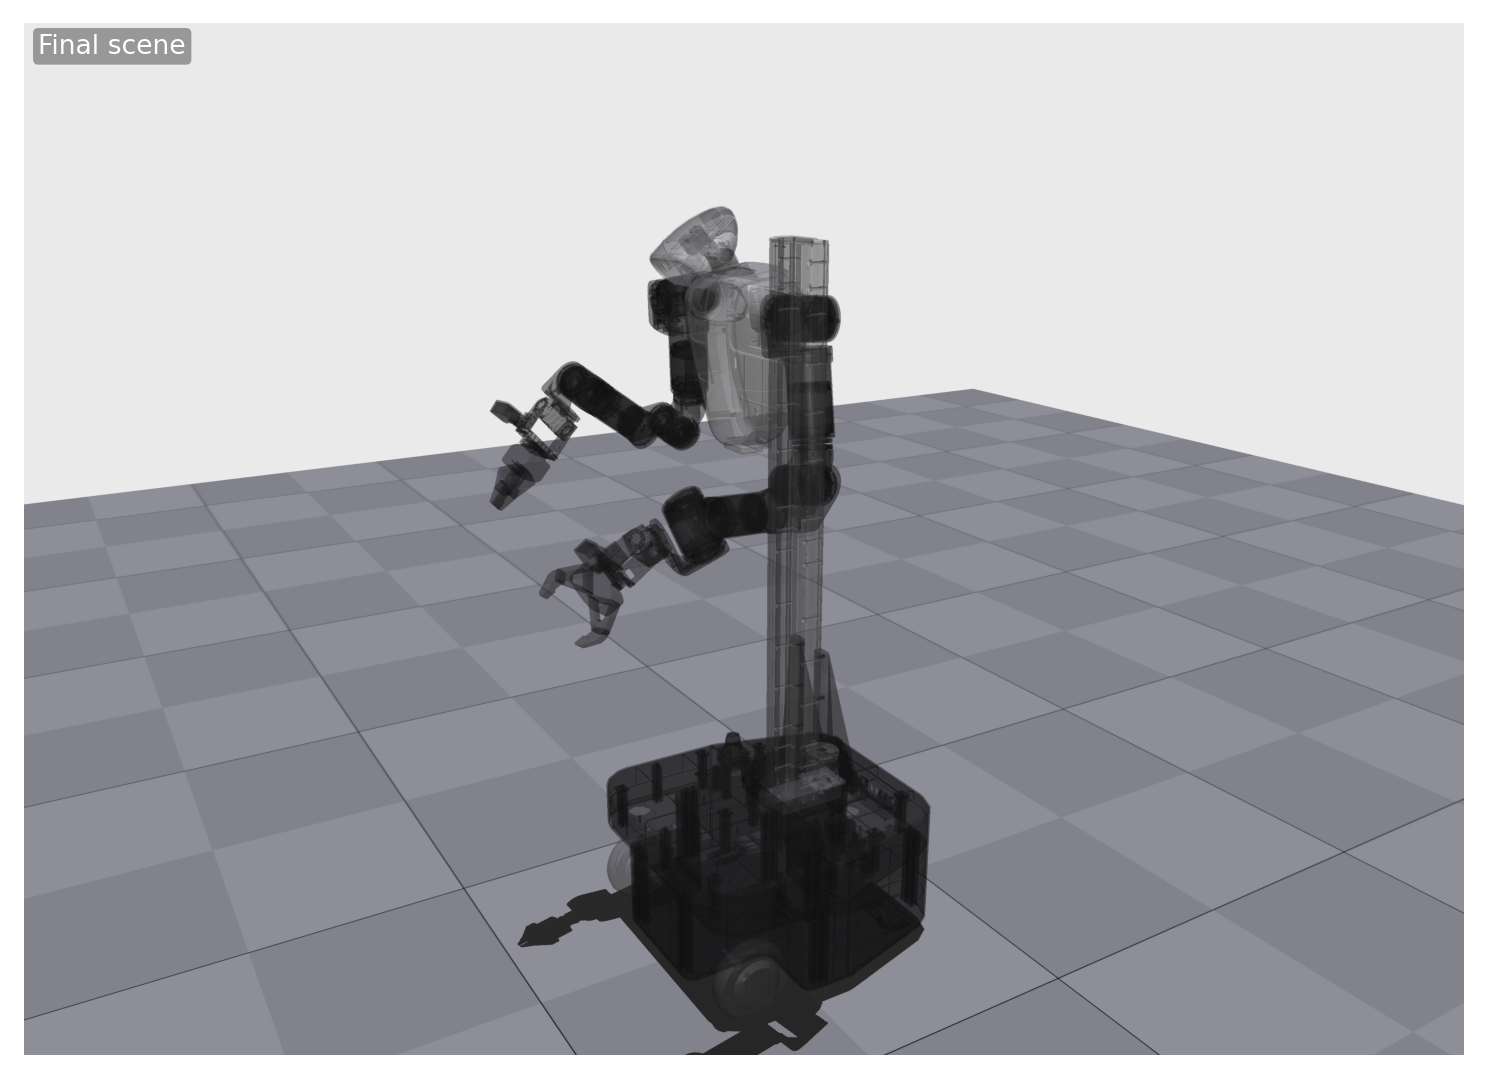

Done.


In [19]:
tmr_input = SimpleTimer(name="Joint Marker",Hz=input_hz,verbose=True)
tmr_robot = SimpleTimer(name="Robot Pub",Hz=robot_hz,verbose=True)
tmr_render = SimpleTimer(name="Render Pub",Hz=render_hz,verbose=True)
tmr_input.start()
tmr_robot.start()
tmr_render.start()
env.reset_wall_time(); env.reset_sim_time()

robot_pub_hz_actual = 0.0
prev_on_flag = False
last_robot_status = None
q_robot = q_use.copy()
collision_status = None
rate_limit_info = None
last_command_message = ""

try:
    while env.is_viewer_alive() and ctrl_radio.isVisible():
        app.processEvents()

        # Read the widget once per pass: Preset/File fire on the toggle edge.
        command_info = handle_sg2_joint_marker_real_command_widget(widget=ctrl_radio,controller=controller)
        on_flag = command_info["robot_on"]
        if on_flag != prev_on_flag:
            print("[Robot Pub] %s"%("ON" if on_flag else "OFF"))
            prev_on_flag = on_flag
        if command_info["message"]:
            last_command_message = command_info["message"]
            print("[Command]",last_command_message)

        if tmr_input.do_run():
            # A drag writes one joint's qpos; the rate limit then decides how much of
            # that motion the robot is allowed to see this tick.
            controller.update()
            rate_limit_info = apply_sg2_joint_rate_limit(
                env          = env,
                joint_names  = command_joint_names,
                q_prev       = q_use,
                dt           = getattr(tmr_input,"dt",1.0/input_hz),
                speed_limits = joint_speed_limits,)
            q_use = np.clip(env.get_qpos(joint_names=command_joint_names),q_use_min,q_use_max)
            env.forward(q=q_use,joint_names=command_joint_names)
            controller.sync_from_env()

            collision_status = None
            if command_info["check_collision"]:
                collision_status = get_sg2_self_collision_status(
                    env                  = env,
                    collision_geom_pairs = collision_geom_pairs,
                    native_backend       = native_backend,
                    safe_margin          = 0.05,
                    signed_distance_topk = 5,)
            tmr_input.end()

        if tmr_robot.do_run():
            robot_result = pub_robot.step(
                get_qmsg_from_qpos(qpos=q_use, q_msg_layout=q_msg_layout), enabled=on_flag)
            robot_pub_hz_actual = (1.0/tmr_robot.sec_elps_diff
                                   if robot_result["sent"] and tmr_robot.sec_elps_diff > 0 else 0.0)
            if robot_result["q_command"] is not None:
                q_robot = robot_result["q_command"][[ROBOT_JOINT_NAMES.index(name) for name in command_joint_names]]
            if robot_result["synchronize"]:
                q_use = robot_result["q_command"][[ROBOT_JOINT_NAMES.index(name) for name in command_joint_names]]
                env.forward(q=q_use, joint_names=command_joint_names)
                for hand_type in SG2_HAND_TYPES:
                    set_sg2_gripper_qpos(env, hand_type, float(q_use[command_joint_names.index(SG2_GRIPPER_DRIVER_JOINT_NAMES[hand_type])]))
                controller.sync_from_env()
            robot_status = (robot_result["state"], robot_result["reason"])
            if robot_status != last_robot_status:
                print("[Robot]", *robot_status)
                last_robot_status = robot_status
            tmr_robot.end()

        if tmr_render.do_run():
            env.plot_global_coordinate_axes()
            env.plot_links_between_bodies(r=0.001)
            controller.draw()
            draw_sg2_self_collision(env,collision_status)
            if command_info["show_eef"]:
                draw_sg2_wrist_frames(env)
            env.viewer_text_overlay("Command",make_sg2_robot_command_overlay_text(on_flag,robot_pub_hz_actual,rate_limit_info),loc="top left")
            env.viewer_text_overlay("Marker",make_sg2_joint_marker_status_text(controller),loc="top left")
            env.viewer_text_overlay("Joint",make_sg2_joint_marker_overlay_text(controller),loc="top left")
            if command_info["show_eef"]:
                env.viewer_text_overlay("EEF",make_sg2_eef_overlay_text(env),loc="top left")
            env.viewer_text_overlay("Collision",make_sg2_self_collision_overlay_text(collision_status),loc="top left")
            env.viewer_text_overlay("Log",last_command_message,loc="top left")
            env.viewer_text_overlay("Bridge", " | ".join(last_robot_status or ("OFF", "waiting")), loc="bottom left")
            env.render()

            send_render_qpos(
                pub_render          = pub_render,
                qpos                = q_robot,
                joint_names         = command_joint_names,
                q_msg_layout        = q_msg_layout,
                msg_type            = "real_joint_marker_ffw_sg2",
                on_flag             = on_flag,
                robot_hz            = robot_hz,
                render_hz           = render_hz,
                robot_pub_hz_actual = robot_pub_hz_actual,
                extra               = make_sg2_joint_marker_render_extra(
                    env              = env,
                    controller       = controller,
                    robot_on         = on_flag,
                    collision_status = collision_status,),)
            tmr_render.end()

except KeyboardInterrupt:
    print("Interrupted.")
finally:
    pub_render.close()
    pub_robot.close()
    ctrl_radio.close()
    if getattr(env,"final_rgb_img",None) is not None:
        imshow(env.final_rgb_img,fig_w=6,title="Final scene",title_fs=8)
    env.close_viewer()
    print("Done.")